# 01 · Preparação e EDA — Case NPS Preditivo (Tech Challenge Fase 1)

**Pergunta de negócio:** o que faz um cliente dar uma nota baixa depois de uma compra, e onde a operação pode agir?

**O que este notebook faz**
1. Carrega a base bruta (sem alterar nada) e checa a qualidade.
2. Sinaliza linhas inconsistentes **sem apagá-las**.
3. Define a target (`nps_score`) e a regra de corte detrator / neutro / promotor.
4. Faz a EDA com foco em negócio: o que move a nota.
5. Salva a base preparada em `data/processed/`.

**Decisões adotadas** (podem ser alteradas em `src/prep.py`):
- Corte: detrator < 7, neutro de 7 até < 9, promotor ≥ 9, sem arredondar a nota.
- Linhas inconsistentes: mantidas e marcadas com colunas `flag_*`.
- `csat_internal_score` e `repeat_purchase_30d` ficam fora de qualquer modelo (vazamento).

In [1]:
import os
import sys
from pathlib import Path

# o notebook roda de dentro de notebooks/; trabalhamos sempre a partir da raiz do repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src import prep

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# paleta: cinza como base, um destaque
GREY, ACCENT = "#B8B8B0", "#2A78D6"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 13,
        "axes.titleweight": "regular",
        "axes.titlelocation": "left",
    }
)
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## 1. Carga e visão geral

In [2]:
raw = prep.load_raw()
print(raw.shape)
raw.head()

(2500, 19)


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.90,0,3,6.50
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.40,0,3,0.00
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.80,0,7,1.50
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.90,0,4,0.30
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.10,0,3,7.90


In [3]:
print("Nulos:", int(raw.isna().sum().sum()))
print("Linhas duplicadas:", int(raw.duplicated().sum()))
print("customer_id únicos:", raw.customer_id.is_unique, "| order_id únicos:", raw.order_id.is_unique)
raw.describe().T

Nulos: 0
Linhas duplicadas: 0
customer_id únicos: True | order_id únicos: True


,count,mean,std,min,25%,50%,75%,max
customer_id,"2,500.00","1,250.50",721.83,1.00,625.75,"1,250.50","1,875.25","2,500.00"
customer_age,"2,500.00",43.40,14.89,18.00,31.00,43.00,56.00,69.00
customer_tenure_months,"2,500.00",61.32,34.48,1.00,31.00,62.00,91.00,119.00
order_id,"2,500.00","51,250.50",721.83,"50,001.00","50,625.75","51,250.50","51,875.25","52,500.00"
order_value,"2,500.00",434.26,289.77,7.76,220.25,375.51,577.29,"1,983.81"
items_quantity,"2,500.00",3.47,1.69,1.00,2.00,3.00,5.00,6.00
discount_value,"2,500.00",29.75,29.23,0.02,8.88,20.94,40.83,230.33
payment_installments,"2,500.00",6.00,3.16,1.00,3.00,6.00,9.00,11.00
delivery_time_days,"2,500.00",8.02,3.77,2.00,5.00,8.00,11.00,14.00
delivery_delay_days,"2,500.00",2.19,1.45,0.00,1.00,2.00,3.00,8.00


## 2. Qualidade dos dados

Não há nulos nem duplicados, mas há **linhas que se contradizem**. Em vez de apagar, marcamos cada uma com uma coluna `flag_*`
e deixamos a decisão de excluir (ou não) para cada análise. Algumas podem ser o próprio problema de negócio, por exemplo
um pedido com reclamação e nenhum contato registrado.

In [4]:
df = prep.prepare(raw)
flags = [c for c in df.columns if c.startswith("flag_")]
quality = pd.DataFrame(
    {"linhas": df[flags].sum(), "% da base": df[flags].mean() * 100}
).round(1)
quality

,linhas,% da base
flag_atraso_maior_que_prazo,121,4.80
flag_desconto_maior_que_valor,35,1.40
flag_resolucao_sem_contato,511,20.40
flag_reclamacao_sem_contato,531,21.20
flag_qualquer,673,26.90


### Esses sinalizadores mudam a leitura da nota?

Se a nota média das linhas sinalizadas for parecida com a das demais, manter ou excluir muda pouco o resultado.
Se for muito diferente, excluir muda a leitura.

In [5]:
rows = []
for f in flags[:-1]:
    rows.append(
        {
            "flag": f,
            "nota média (sinalizadas)": df.loc[df[f], "nps_score"].mean(),
            "nota média (demais)": df.loc[~df[f], "nps_score"].mean(),
        }
    )
pd.DataFrame(rows).set_index("flag").round(2)

,nota média (sinalizadas),nota média (demais)
flag,,
flag_atraso_maior_que_prazo,2.26,4.49
flag_desconto_maior_que_valor,4.34,4.38
flag_resolucao_sem_contato,5.45,4.10
flag_reclamacao_sem_contato,5.41,4.10


**Leitura:** a diferença é grande. As linhas com atraso maior que o tempo total têm nota média de 2,3 contra 4,5 nas demais, e as linhas com reclamação ou resolução sem contato registrado têm nota mais alta (cerca de 5,4 contra 4,1). Excluir essas linhas mudaria os resultados, e a primeira marca pega justamente os casos mais críticos. Por isso elas ficam na base.

### Vazamento de informação (leakage)

`repeat_purchase_30d` é a nota disfarçada e `csat_internal_score` é uma pesquisa de satisfação medida junto com ela.
`csat_internal_score` tem relação forte com a nota e não sabemos se é medida antes dela. Por segurança, nenhuma das duas entra em modelo que preveja a nota.

In [6]:
print("repeat_purchase_30d == (nps_score >= 8) em todas as linhas:",
      bool((df.repeat_purchase_30d == (df.nps_score >= 8).astype(int)).all()))
print("Correlação de Spearman csat x nps:", round(df.csat_internal_score.corr(df.nps_score, method="spearman"), 2))
print("csat_internal_score == 0:", int((df.csat_internal_score == 0).sum()), "linhas")

repeat_purchase_30d == (nps_score >= 8) em todas as linhas: True
Correlação de Spearman csat x nps: 0.56
csat_internal_score == 0: 462 linhas


## 3. Target e regra de corte

A nota (`nps_score`) é **fracionada** (101 valores distintos, só 17% são inteiros). Por isso o corte é explícito e a nota não é arredondada.

In [7]:
print("Valores distintos de nps_score:", df.nps_score.nunique())
print("Parte inteira:", round((df.nps_score % 1 == 0).mean() * 100, 1), "%")

dist = df.nps_class.value_counts().reindex(["detrator", "neutro", "promotor"])
resumo = pd.DataFrame({"pedidos": dist, "%": dist / len(df) * 100}).round(1)
display(resumo)
print(f"NPS = {prep.nps_value(df.nps_class):.0f} pontos")

Valores distintos de nps_score: 101
Parte inteira: 17.0 %


,pedidos,%
nps_class,,
detrator,2109,84.40
neutro,281,11.20
promotor,110,4.40


NPS = -80 pontos


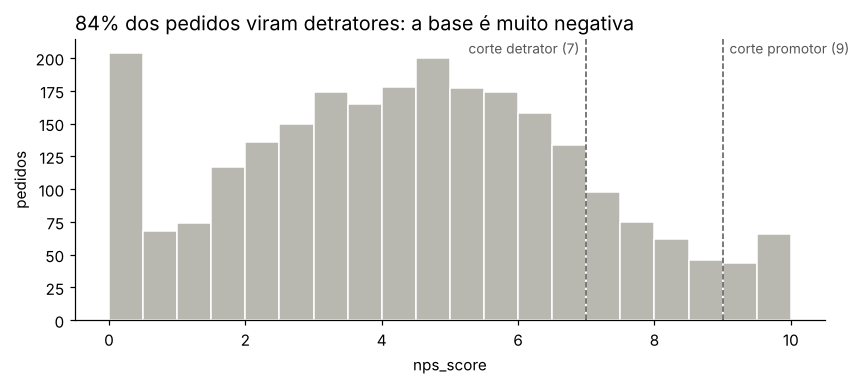

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df.nps_score, bins=np.arange(0, 10.5, 0.5), color=GREY, edgecolor="white")
ax.axvline(prep.CUT_DETRATOR, color="#555", ls="--", lw=1)
ax.axvline(prep.CUT_PROMOTOR, color="#555", ls="--", lw=1)
ax.text(prep.CUT_DETRATOR - 0.1, ax.get_ylim()[1] * 0.95, "corte detrator (7)", ha="right", fontsize=9, color="#555")
ax.text(prep.CUT_PROMOTOR + 0.1, ax.get_ylim()[1] * 0.95, "corte promotor (9)", ha="left", fontsize=9, color="#555")
ax.set_title(f"{resumo.loc['detrator', '%']:.0f}% dos pedidos viram detratores: a base é muito negativa")
ax.set_xlabel("nps_score")
ax.set_ylabel("pedidos")
fig.tight_layout()
fig.savefig(FIG / "01_distribuicao_nota.png")
plt.show()

## 4. EDA com foco em negócio: o que move a nota?

Primeira leitura com correlação de Spearman (não exige que a relação seja linear). São leituras **exploratórias**, ainda sem teste de hipótese.
`csat_internal_score` e `repeat_purchase_30d` ficam de fora.

In [9]:
num_cols = [
    c for c in raw.select_dtypes("number").columns
    if c not in ["nps_score", *prep.LEAKAGE_COLS, "customer_id", "order_id"]
]
corr = df[num_cols].corrwith(df.nps_score, method="spearman")
corr = corr.reindex(corr.abs().sort_values().index)  # mais forte no topo
corr.round(2).to_frame("spearman com nps_score")

,spearman com nps_score
delivery_time_days,0.00
items_quantity,0.01
customer_age,-0.01
discount_value,0.01
customer_tenure_months,-0.01
delivery_attempts,0.03
payment_installments,0.03
order_value,0.04
freight_value,-0.04
resolution_time_days,-0.19


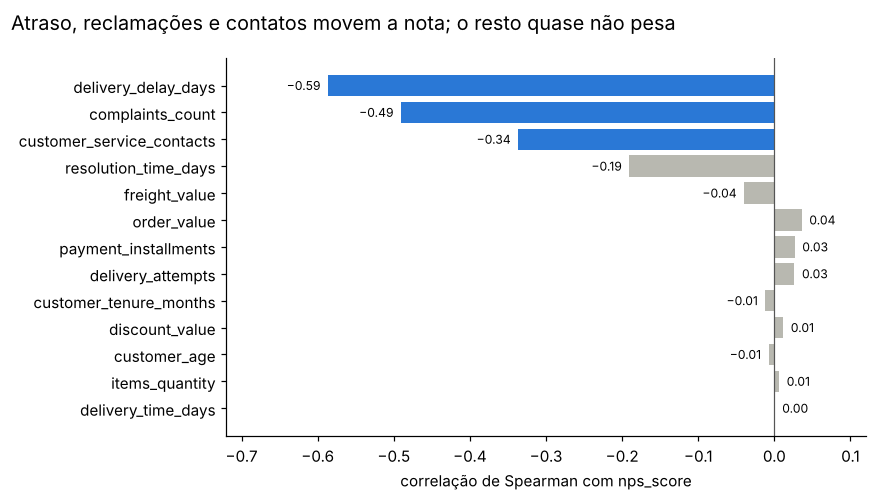

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.6))
cores = [ACCENT if abs(v) >= 0.3 else GREY for v in corr.values]
ax.barh(corr.index, corr.values, color=cores)
ax.axvline(0, color="#555", lw=0.8)
for y, v in enumerate(corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:.2f}".replace("-", "−"), va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.set_xlim(-0.72, 0.12)
fig.suptitle("Atraso, reclamações e contatos movem a nota; o resto quase não pesa", x=0.01, ha="left", fontsize=13)
ax.set_xlabel("correlação de Spearman com nps_score")
fig.tight_layout()
fig.savefig(FIG / "02_correlacao_nota.png")
plt.show()

### 4.1 O atraso é o maior fator, e o que pesa é o prazo prometido

O tempo total de entrega (`delivery_time_days`) tem correlação zero com a nota; o atraso em relação ao combinado tem a maior. O cliente reage à promessa quebrada, não à demora em si.

In [11]:
faixas = pd.cut(df.delivery_delay_days, [-1, 0, 1, 2, 3, 5, 99], labels=["0", "1", "2", "3", "4–5", "6+"])
por_atraso = df.groupby(faixas, observed=True).agg(
    pedidos=("nps_score", "size"),
    nota_media=("nps_score", "mean"),
    pct_detrator=("nps_class", lambda s: (s == "detrator").mean() * 100),
).round(1)
por_atraso

,pedidos,nota_media,pct_detrator
delivery_delay_days,,,
0,277,6.90,51.60
1,615,5.50,74.00
2,646,4.60,87.90
3,525,3.40,96.80
4–5,386,2.20,99.50
6+,51,0.80,100.00


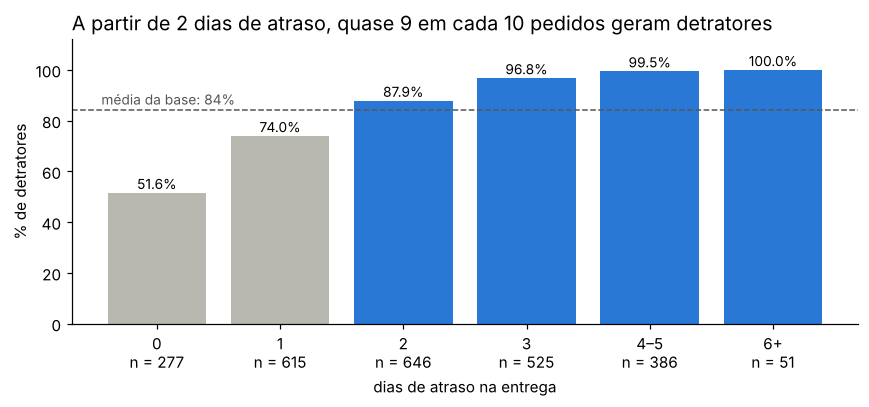

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
cores = [ACCENT if v >= 85 else GREY for v in por_atraso.pct_detrator]
ax.bar(por_atraso.index.astype(str), por_atraso.pct_detrator, color=cores)
media = (df.nps_class == "detrator").mean() * 100
ax.axhline(media, color="#555", ls="--", lw=1)
ax.text(-0.45, media + 2, f"média da base: {media:.0f}%", ha="left", fontsize=9, color="#555")
for i, (n, v) in enumerate(zip(por_atraso.pedidos, por_atraso.pct_detrator)):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xticks(range(len(por_atraso)))
ax.set_xticklabels([f"{k}\nn = {n}" for k, n in zip(por_atraso.index.astype(str), por_atraso.pedidos)])
ax.set_ylim(0, 112)
ax.set_title("A partir de 2 dias de atraso, quase 9 em cada 10 pedidos geram detratores")
ax.set_xlabel("dias de atraso na entrega")
ax.set_ylabel("% de detratores")
fig.tight_layout()
fig.savefig(FIG / "03_detratores_por_atraso.png")
plt.show()

### 4.2 Atendimento: reclamações e contatos

Reclamações e contatos pesam bastante, mas têm pouca ligação com o atraso: a correlação entre atraso e contatos é próxima de zero e entre atraso e reclamações é 0,19. Reclamações e contatos, por outro lado, andam juntos (0,74), então medem em boa parte o mesmo problema.
Isso sugere que a nota cai por **mais de uma causa**, e que melhorar só a logística não resolve tudo.

In [13]:
cols = ["delivery_delay_days", "customer_service_contacts", "complaints_count"]
print(df[cols].corr(method="spearman").round(2))
print()
print(df.groupby("complaints_count").nps_score.agg(["size", "mean"]).round(2).rename(columns={"size": "pedidos", "mean": "nota_media"}))

                           delivery_delay_days  customer_service_contacts  \
delivery_delay_days                       1.00                      -0.02   
customer_service_contacts                -0.02                       1.00   
complaints_count                          0.19                       0.74   

                           complaints_count  
delivery_delay_days                    0.19  
customer_service_contacts              0.74  
complaints_count                       1.00  

                  pedidos  nota_media
complaints_count                     
0                      23        8.52
1                     122        7.77
2                     277        6.05
3                     507        4.91
4                     600        4.22
5                     444        3.65
6                     266        3.06
7                     169        2.81
8                      63        2.07
9                      16        2.49
10                     11        2.28
11          

### 4.3 O perfil do cliente quase não importa

Região, idade e tempo de casa deixam a nota média praticamente igual. Nesta base, não há um "tipo de cliente" insatisfeito; o problema está na **operação**.

In [14]:
print(df.groupby("customer_region").nps_score.agg(["size", "mean"]).round(2))
print()
for c in ["customer_age", "customer_tenure_months"]:
    q = pd.qcut(df[c], 4, duplicates="drop")
    print(c)
    print(df.groupby(q, observed=True).nps_score.mean().round(2).to_string())
    print()

grupos = [g.nps_score.values for _, g in df.groupby("customer_region")]
h, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis entre regiões: H = {h:.2f}, p = {p:.3f}")

                 size  mean
customer_region            
Centro-Oeste      468  4.21
Nordeste          485  4.42
Norte             506  4.38
Sudeste           520  4.37
Sul               521  4.49

customer_age
customer_age
(17.999, 31.0]   4.58
(31.0, 43.0]     4.19
(43.0, 56.0]     4.38
(56.0, 69.0]     4.36

customer_tenure_months
customer_tenure_months
(0.999, 31.0]   4.41
(31.0, 62.0]    4.40
(62.0, 91.0]    4.37
(91.0, 119.0]   4.34

Kruskal-Wallis entre regiões: H = 3.38, p = 0.497


### 4.4 Quanto vale evitar o atraso?

Comparação simples entre pedidos **sem atraso** e **com atraso de 2 dias ou mais**.
Não prova causalidade (a base é observacional), mas dimensiona o tamanho do que está em jogo.

In [15]:
sem = df.loc[df.delivery_delay_days == 0, "nps_score"]
com = df.loc[df.delivery_delay_days >= 2, "nps_score"]
u, p = stats.mannwhitneyu(sem, com)
print(f"Nota média sem atraso: {sem.mean():.2f} | com 2+ dias: {com.mean():.2f} | diferença: {sem.mean() - com.mean():.2f}")
print(f"Mann-Whitney: p = {p:.2e}")
print(f"Pedidos com 2+ dias de atraso: {len(com)} ({len(com) / len(df) * 100:.0f}% da base)")

Nota média sem atraso: 6.86 | com 2+ dias: 3.51 | diferença: 3.35
Mann-Whitney: p = 2.26e-82
Pedidos com 2+ dias de atraso: 1608 (64% da base)


## 5. Salvando a base preparada

A base preparada guarda as colunas originais, as flags de qualidade e a classe de NPS. Nada foi removido.
As colunas de vazamento continuam na base (para análise) e devem ser descartadas no momento de treinar qualquer modelo (`prep.LEAKAGE_COLS`).

In [16]:
prep.PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(prep.PROCESSED_PATH, index=False)
print("Salvo em", prep.PROCESSED_PATH, "|", df.shape)

Salvo em data/processed/nps_preparado.csv | (2500, 25)


## 6. Limitações e próximos passos

- **Sem data:** não existe coluna temporal, então não dá para separar treino e teste por período nem ver tendência. Um eventual modelo usa divisão aleatória estratificada, e isso deve ser dito.
- **Base provavelmente sintética:** padrões muito regulares (por exemplo o `repeat_purchase_30d` determinístico) sugerem dados simulados. Conclusões valem para esta base, não necessariamente para a operação real.
- **Correlação não é causa:** os números acima apontam onde olhar, não provam o efeito de uma ação.
- **Próximos passos:** texto de entendimento do negócio e da target, storytelling dos slides e, se o prazo permitir, um modelo enxuto sem as colunas de vazamento.